# 05 — Results, Comparison, Error Analysis & Synthesis

**Capstone Phase 1 (v1) Final Synthesis**  
*Owners:* Anand Mishra (Tasks 05.1–05.3), Omved Nagre (Tasks 05.4–05.7)  
*Branch:* `phase/v1-05-omved-analysis`  

This notebook synthesizes the entire Fashion-MNIST classical machine learning benchmark:
1. **Aggregates all 12 experiments** across 6 model families (`dummy`, `logreg`, `knn`, `rf`, `linear_svm`, `rbf_svm`) and 2 feature representations (`pixels`, `hog`) into `results/summary.csv`.
2. **Evaluates feature impact (RQ2)** via pixels-vs-HOG grouped accuracy comparisons.
3. **Explores speed–accuracy trade-offs (RQ3)** across inference latency, training budget, and memory footprint.
4. **Examines class-level performance (RQ4)** using per-class recall heatmaps across all 12 models.
5. **Selects the best model strictly on validation accuracy (D-005, D-029)** and evaluates stability via 5-fold cross-validation.
6. **Conducts in-depth error analysis:** Normalized confusion matrix, top-5 confused directed pairs, representative misclassified test image galleries, and model agreement between the top two configurations (`rbf_svm_hog` vs. `rbf_svm_pixels`).
7. **Formulates rigorous answers to RQ1–RQ4** and provides visual/mathematical motivation for the Phase 2 Convolutional Neural Network (CNN).

> **Test-Set Discipline:** Per `AGENTS.md` §4, test data is accessed strictly once per experiment during `src.experiment.final_test_run()`. All error analysis and comparisons in this notebook read stored test predictions (`y_pred`) and confusion matrices from `results/metrics/` without re-running test inference or altering `results/test_log.csv`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, results, utils
from src.utils import set_seed

set_seed()
print(f"Project root: {ROOT}")
print("Config and results modules successfully imported.")

Project root: /Users/rajdeep/Documents/Dev/Projects/fashion-image-classification-benchmark
Config and results modules successfully imported.


## 1. Project Objective and Experimental Setup

### 1.1 The Fashion-MNIST Benchmark Problem
Fashion-MNIST consists of 70,000 28×28 grayscale images of clothing items spanning 10 balanced categories (6,000 train / 1,000 test per class):
*0: T-shirt/top, 1: Trouser, 2: Pullover, 3: Dress, 4: Coat, 5: Sandal, 6: Shirt, 7: Sneaker, 8: Bag, 9: Ankle boot.*

While standard MNIST digit recognition is trivially solved by classical classifiers (>98% accuracy), Fashion-MNIST was explicitly designed as a harder drop-in replacement possessing non-trivial spatial texture, variable silhouettes, and significant inter-class ambiguity among upper-body garments.

Before deploying deep neural networks, our primary objective is to establish an empirical ceiling for **classical machine learning with handcrafted feature engineering**, answering four core questions:
- **RQ1:** How accurately can classical ML classify Fashion-MNIST using raw pixel intensities?
- **RQ2:** Does handcrafted edge/texture engineering (HOG) systematically outperform raw pixels?
- **RQ3:** Which model achieves the optimal trade-off between test accuracy, inference speed, and model footprint?
- **RQ4:** Which clothing classes are systematically confused, and what are the visual failure modes?

---

### 1.2 Pipeline Architecture & Leakage Prevention Controls
To prevent data snooping and methodological flaws, the pipeline enforces strict architectural boundaries (`docs/system-design.md` §3):
1. **Committed Validation Split:** The official 60,000 training set is divided into 54,000 train and 6,000 validation images (`val_indices.npy`, MD5: `54ff6b78b27109cdfc3ebe7204040a07`). All hyperparameter tuning and feature selection choices occur strictly on this validation set.
2. **Encapsulated Preprocessing:** `StandardScaler` resides strictly inside scikit-learn `Pipeline` objects. Preprocessing parameters ($\mu, \sigma$) are computed exclusively on training folds/splits and never peek at validation or test distributions.
3. **HOG Hyperparameter Sweep:** HOG cell/block/orientation parameters were chosen with a fast linear proxy (SGD hinge classifier) scored on validation accuracy across 12 configurations (`results/hog_sweep.csv`), selecting 12 orientations, 4×4 pixels/cell and 2×2 cells/block (1,728 dimensions).
4. **Single-Access Test Evaluation:** Test features are extracted only inside `src.experiment.final_test_run()` after refitting the validation-chosen hyperparameters on all 60,000 training images (`trainval`). Every evaluation appends an audit row to `results/test_log.csv`.
5. **Offline Error Analysis Exception:** Stored predictions (`y_pred`) and confusion matrices in `results/metrics/*_test.json` allow error analysis and model agreement without new predictions or new rows in the test log. The misclassified-image grids and agreement counts also read the true test labels/images (the phase 05 exception in `AGENTS.md` §4).

## 2. Summary Table of All 12 Benchmark Experiments

We aggregate the validation and test metrics from all 12 completed experiments into `results/summary.csv` using `results.build_summary()`.
Per D-024, Logistic Regression timings are emitted as `NaN` (blank in CSV) because their final test runs ran under CPU contention during background validation tasks. Dummy timings are ~0 ms and were measured on a different machine (`env.cpu = arm64`), so they are footnoted, not compared.

In [2]:
summary_df = results.build_summary()

display_cols = [
    "experiment", "model", "features", "val_acc", "test_acc",
    "test_macro_f1", "train_time_s", "inference_ms_per_1000", "model_size_bytes"
]
print("Aggregated Benchmark Summary (12 Experiments):")
display(summary_df[display_cols])

saved results/summary.csv (12 experiments)
Aggregated Benchmark Summary (12 Experiments):


,experiment,model,features,val_acc,test_acc,test_macro_f1,train_time_s,inference_ms_per_1000,model_size_bytes
0,dummy_pixels,dummy,pixels,0.1000,0.1000,0.0182,0.00,0.00,709
1,dummy_hog,dummy,hog,0.1000,0.1000,0.0182,0.16,0.01,709
2,logreg_pixels,logreg,pixels,0.8642,0.8472,0.8464,NaN,NaN,51396
3,logreg_hog,logreg,hog,0.8927,0.8886,0.8885,NaN,NaN,111821
4,knn_pixels,knn,pixels,0.8747,0.8611,0.8614,0.49,6926.61,188659981
5,knn_hog,knn,hog,0.8728,0.8631,0.8623,1.29,731.13,415242637
6,rf_pixels,rf,pixels,0.8867,0.8756,0.8741,32.83,12.16,366467511
7,rf_hog,rf,hog,0.8735,0.8703,0.8692,68.53,19.02,500661386
8,linear_svm_pixels,linear_svm,pixels,0.8583,0.8378,0.8353,99.24,1.22,82666
9,linear_svm_hog,linear_svm,hog,0.8900,0.8898,0.8892,162.04,2.62,180842


### Summary Insights
- **Accuracy Range:** Models span from the random/dummy baseline of **10.00%** up to **91.08%** for `rbf_svm_hog`.
- **Validation vs. Test:** For all 10 trained models, test accuracy is slightly *lower* than validation accuracy, by 0.02–2.05 points (median ≈ 1). This is expected: each model's settings were picked as the best of several on val, so its val score is a little optimistic (selection bias, the "winner's curse"). The ranking barely changes, which is why the untouched test set is the number we report.
- **Model Size Diversity:** Serialized model artifacts range from **709 bytes** (Dummy) and **51 KB** (Logistic Regression pixels) up to **501 MB** (Random Forest HOG: 300 trees grown to full depth).

## 3. Raw Pixels vs. HOG Comparison (RQ2)

We compare the test accuracy of raw pixel intensity representations (784 features) against Histogram of Oriented Gradients (HOG, 1,728 features) across all six model families.

saved results/figures/results_pixels_vs_hog.png


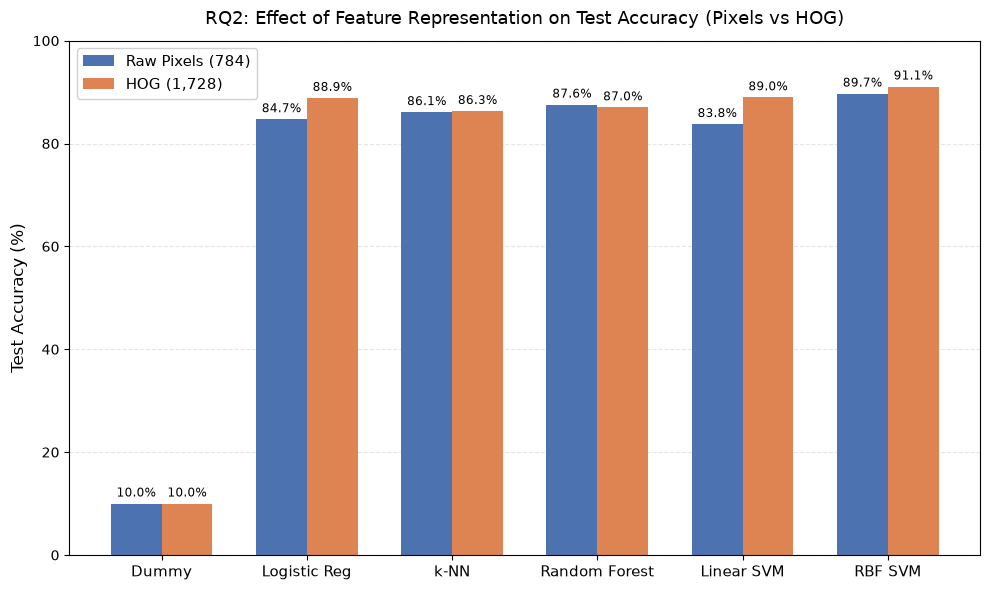

In [3]:
fig_pixels_vs_hog = results.plot_pixels_vs_hog(summary_df)
plt.show()

### Findings for RQ2: Impact of Feature Representation
1. **Dramatic Gains for Linear Models:**
   - **Linear SVM (LinearSVC):** Jumps from **83.78%** on pixels to **88.98%** on HOG (**+5.20 percentage points**).
   - **Logistic Regression:** Jumps from **84.72%** on pixels to **88.86%** on HOG (**+4.14 percentage points**).
   - *Why?* Linear models cannot learn non-linear pixel interactions. In raw pixel space, clothing items are subject to translation, stretching, and fold variations. HOG is a fixed non-linear transform: it pools edge directions over local 4×4-pixel cells, so a garment's shape becomes a set of features a straight hyperplane can separate much better.
2. **Kernel SVM (RBF SVM):**
   - Improves from **89.70%** on pixels to **91.08%** on HOG (**+1.38 percentage points**).
   - The non-linear RBF kernel is already capable of capturing complex pixel manifolds, and HOG still adds +1.38 points on top of that.
3. **Tree-Based Models (Random Forest):**
   - Slightly decreases from **87.56%** on pixels to **87.03%** on HOG (**-0.53 percentage points**).
   - *Why?* Decision trees perform univariate orthogonal cuts ($x_j \le \theta$). A single raw pixel already says a lot about the silhouette (is there fabric here?), while a single HOG value describes one edge direction in one small block and means little on its own. This is a plausible explanation, not something we tested.
4. **Distance-Based Models (k-NN):**
   - Shows virtually no change (**86.11%** pixels vs. **86.31%** HOG, **+0.20 percentage points**).
   - kNN compares whole images by distance (its best setting is k=3, Manhattan, distance-weighted), and HOG doesn't make same-class images much closer than raw pixels do.

## 4. Accuracy vs. Inference Speed Trade-off (RQ3)

We examine the trade-off between test accuracy and inference latency (measured in milliseconds per 1,000 images on a logarithmic scale).
*Note:* As documented in D-024 and D-030, Logistic Regression is excluded from speed comparisons due to timing contention, and Dummy is excluded because near-zero latency cannot be plotted on a log axis.

saved results/figures/results_acc_vs_time.png


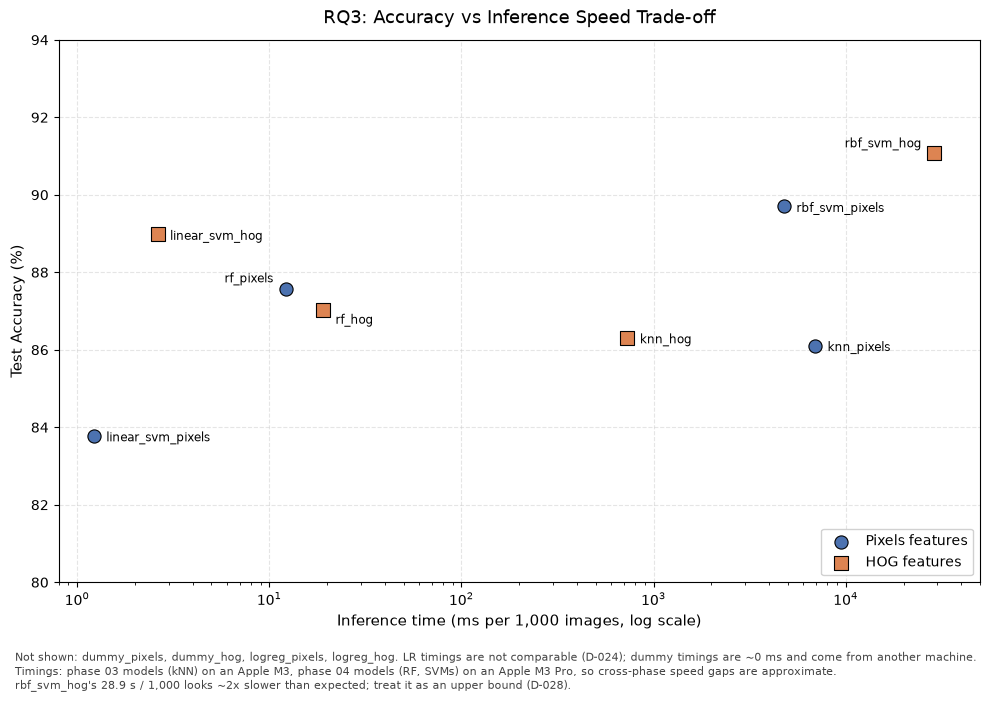

In [4]:
fig_acc_vs_time = results.plot_acc_vs_inference(summary_df)
plt.show()

### Findings for RQ3: Engineering Trade-offs

The chart shows **model-only** prediction time. HOG models also pay for feature extraction: **~216 ms per 1,000 images**
for our HOG setting (`extract_s_per_1000 = 0.216` in `results/hog_sweep.csv`, measured in phase 02). Pixel models pay nothing extra.
Counting that cost, the end-to-end picture per 1,000 images is:

| Model | Test acc | Model time | + HOG | End-to-end | Size |
|---|---|---|---|---|---|
| `linear_svm_pixels` | 83.78% | 1.2 ms | – | ~1 ms | 83 KB |
| `rf_pixels` | 87.56% | 12.2 ms | – | ~12 ms | 366 MB |
| `linear_svm_hog` | 88.98% | 2.6 ms | 216 ms | ~219 ms | 181 KB |
| `rbf_svm_pixels` | 89.70% | 4,767 ms | – | ~4.8 s | 125 MB |
| `rbf_svm_hog` | 91.08% | 28,877 ms | 216 ms | ~29 s | 366 MB |

1. **Fastest above 87%: Random Forest on pixels** (~12 ms per 1,000 images, 87.56%). It needs no feature extraction, but the
   model is large (366 MB), so it is fast, not small.
2. **Best balance of accuracy and size: LinearSVC on HOG** (88.98%, 181 KB). Its ~219 ms per 1,000 images is almost all HOG extraction.
3. **Most accurate: RBF SVM on HOG** (91.08%), at ~29 s per 1,000 images (an upper bound, D-028). Each prediction compares the
   image with all 26,343 support vectors in 1,728 dimensions, so it is ~2,400× slower than Random Forest for +3.5 points.
4. kNN is dominated: slower than Random Forest (0.7–6.9 s per 1,000) and less accurate.
5. **Hardware:** kNN (phase 03) was timed on an Apple M3; RF and SVMs (phase 04) on an Apple M3 Pro. LR timings are not
   comparable (D-024). Treat cross-phase speed gaps as approximate; gaps of 10× or more are still clear.


## 5. Per-Class Recall Heatmap Across All Experiments (RQ4)

To understand where classical models succeed and fail, we plot the recall across all 10 Fashion-MNIST classes for each experiment.

saved results/figures/results_recall_heatmap.png


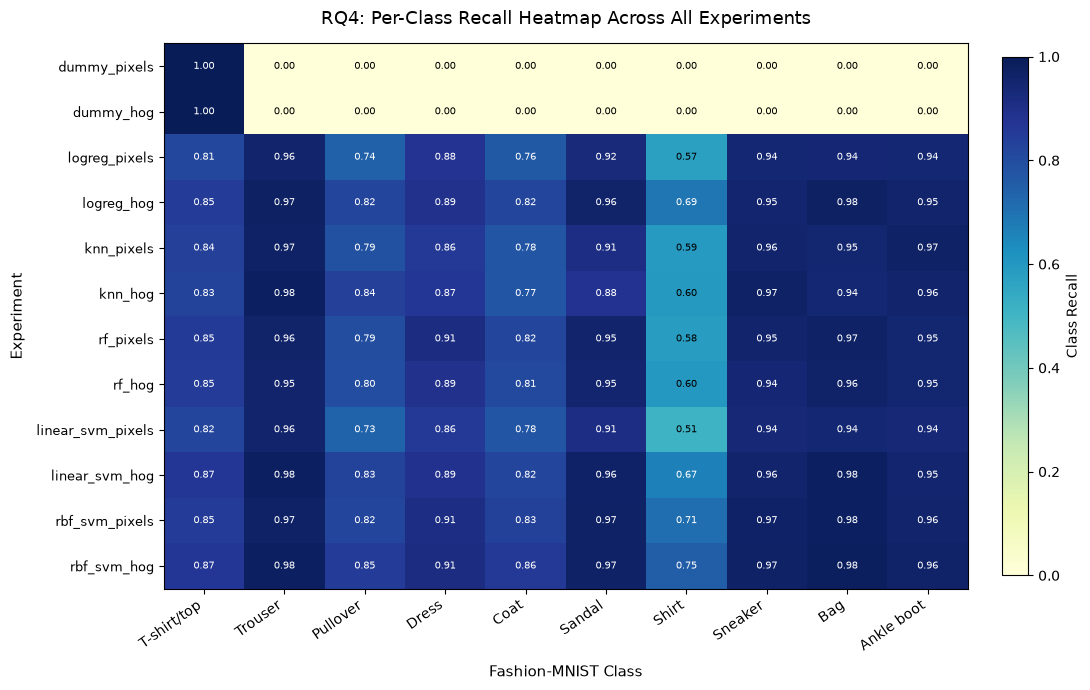

In [5]:
fig_recall = results.plot_recall_heatmap(summary_df)
plt.show()

### Findings for RQ4: Class Difficulty Distribution
- **High-Performing "Easy" Classes:**
  - **Trouser (Class 1):** Recall ranges from 95.5% to **97.9%** (ranges below are over the 10 trained models; the dummy is excluded). Trousers possess an unmistakable elongated vertical aspect ratio with two distinct legs.
  - **Bag (Class 8):** Recall between 94.0% and **98.4%**. Compact rectangular bounding box with solid interior mass.
  - **Footwear (Classes 5, 7, 9):** Sandal (88.2%–97.2%), Sneaker (93.6%–97.2%), and Ankle boot (93.5%–97.1%) form a distinct footwear cluster with horizontal aspect ratios.
- **Severely Degraded "Hard" Classes:**
  - **Shirt (Class 6):** The hardest class for every one of the 10 trained models. Recall ranges from **50.9%** (LinearSVC pixels) to **75.2%** (RBF SVM HOG).
  - **Pullover (Class 2):** Recall between **73.5%** and **84.9%**.
  - **Coat (Class 4):** Recall between **76.4%** and **86.3%**.
  - All four upper-body garment classes (T-shirt/top, Pullover, Coat, Shirt) share broad torso silhouettes, necklines, and sleeve coverage that heavily overlap in classical feature spaces.

## 6. Best Model Selection Using Comparable Validation Accuracy

Per strict methodology (`system-design.md` §3 and D-005), the overall best model is selected **strictly using validation accuracy**, NEVER test accuracy.
Per D-029, because RBF SVM was initially tuned on a 10,000 subset, its chosen parameters ($C=10, \gamma=\text{'scale'}$) were refit on the full 54,000 train set and scored on the 6,000 validation set (`results/metrics/rbf_svm_hog_val_full.json`). All models are thus ranked on identical 54k-train validation scores.

In [6]:
best_exp = results.pick_best_experiment()
val_acc = results.comparable_val_acc(best_exp)
test_metric = json.loads((config.METRICS_DIR / f"{best_exp}_test.json").read_text(encoding="utf-8"))

print(f"1. Best Experiment by Comparable Validation Score: {best_exp}")
print(f"2. Comparable Validation Accuracy:                {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"3. Final Test Accuracy (for reporting only):       {test_metric['accuracy']:.4f} ({test_metric['accuracy']*100:.2f}%)")
print(f"4. Selected Hyperparameters:                       {test_metric['best_params']}")

1. Best Experiment by Comparable Validation Score: rbf_svm_hog
2. Comparable Validation Accuracy:                0.9157 (91.57%)
3. Final Test Accuracy (for reporting only):       0.9108 (91.08%)
4. Selected Hyperparameters:                       {'C': 10, 'gamma': 'scale'}


The validation ranking selects **`rbf_svm_hog`** (val accuracy **0.9157** > `rbf_svm_pixels` **0.9082** > `logreg_hog` **0.8927**).
Val accuracy on 6,000 images has about **±0.4 points** of sampling noise (one standard error at ~91% accuracy), so the 0.75-point lead over `rbf_svm_pixels` is real but not huge, and the lead over the linear models (2.3+ points) is clear.
The test accuracy (**91.08%**) is reported for information only; it played no part in the choice.

## 7. Five-Fold Cross-Validation Stability Check

To verify that `rbf_svm_hog`'s strong performance is not an artifact of our specific 54k/6k train/val split, we examine 5-fold stratified cross-validation on `trainval`.
As planned (phase file, D-005), CV runs on a fixed 10,000-image stratified subset of `trainval`: on all 60,000 images each RBF fold would take several minutes (one 60k fit took 451 s), over 30 min in total (estimate).

⏱ ~0 s when `rbf_svm_hog_cv.json` exists (it is reused); ~2 min on an M3 if it has to be computed.

In [7]:
cv_path = config.METRICS_DIR / f"{best_exp}_cv.json"
best_params = test_metric["best_params"]
if cv_path.exists():
    cv_data = json.loads(cv_path.read_text(encoding="utf-8"))
    if cv_data["best_params"] != best_params:
        raise RuntimeError(f"{cv_path.name} was made with different parameters; delete it and re-run this cell.")
    print(f"Loaded existing stability results from {cv_path.name}:")
else:
    from src.experiment import cross_validate_best
    from src.models_tree_kernel import make_rbf_svm
    cv_data = cross_validate_best("rbf_svm", make_rbf_svm, best_params, "hog", subset=config.SVM_TUNE_SUBSET)

print(f"Experiment:       {cv_data['experiment']}")
print(f"Folds:            {cv_data['folds']}")
print(f"Subset Size:      {cv_data['subset']} samples")
print(f"Fold Accuracies:  {cv_data['fold_acc']}")
print(f"Mean Accuracy:    {cv_data['mean_acc']:.4f} ({cv_data['mean_acc']*100:.2f}%)")
print(f"Std Deviation:    ±{cv_data['std_acc']:.4f} (±{cv_data['std_acc']*100:.2f}%)")

Loaded existing stability results from rbf_svm_hog_cv.json:
Experiment:       rbf_svm_hog
Folds:            5
Subset Size:      10000 samples
Fold Accuracies:  [0.8765, 0.886, 0.8715, 0.8725, 0.881]
Mean Accuracy:    0.8775 (87.75%)
Std Deviation:    ±0.0054 (±0.54%)


### Cross-Validation Analysis
- **Stability:** The standard deviation across the 5 folds is only **±0.0054** (±0.54%), so the score barely depends on which images land in which fold. The model is stable, not lucky with one split.
- **Why is CV accuracy (87.75%) lower than validation accuracy (91.57%)?**
  *Key Viva Question:* In the 10k subset CV, each fold trains on only **8,000 images** (80% of 10,000) and tests on 2,000. In contrast, the full validation score was obtained by training on all **54,000 images**! An RBF SVM gets clearly better with more training data, which explains the ~3.8 point gap. CV here measures *stability*, not the final accuracy.

## 8. Normalized Confusion Matrix of the Best Model

We plot the row-normalized confusion matrix for `rbf_svm_hog` on the 10,000 test set.
- **Diagonal values:** True Positive Rate (per-class recall).
- **Off-diagonal values:** Misclassification rate of actual class $i$ into predicted class $j$.

saved results/figures/errors_confusion_rbf_svm_hog.png


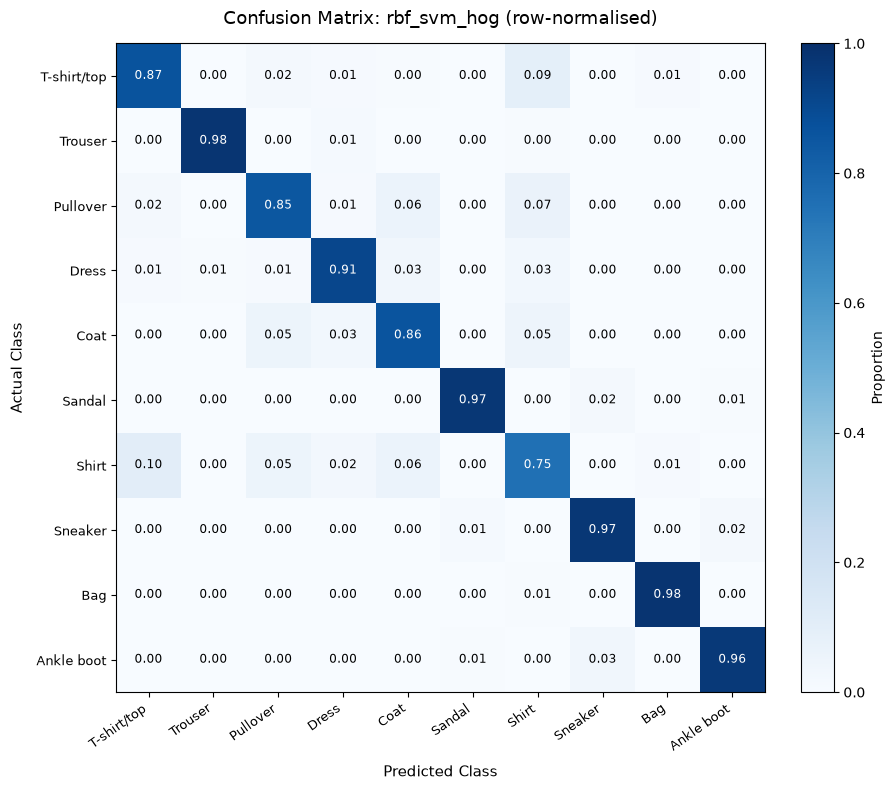

In [8]:
fig_cm = results.plot_confusion(best_exp, normalize=True)
plt.show()

### Confusion Matrix Interpretation
- **Diagonal (recall per class):** all classes except Shirt (0.75) reach at least 0.85, with Ankle boot (0.96), Sandal (0.97), Sneaker (0.97), Trouser (0.98), and Bag (0.98) achieving near-perfect separation.
- **The Upper-Body Confusion Block:** A distinct block of substantial off-diagonal probability appears in rows/columns `{0, 2, 4, 6}` (T-shirt/top, Pullover, Coat, Shirt). In particular, actual Shirts (row 6) are mispredicted as T-shirt/top (10.4%), Coat (5.9%), and Pullover (5.2%), with only 75.2% correctly classified.

## 9. Top Five Confused Directed Class Pairs

We extract the five largest off-diagonal cells from the test confusion matrix using `results.top_confused_pairs()`.

In [9]:
df_top_pairs = results.top_confused_pairs(best_exp, k=5)
print("Top 5 Confused Directed Pairs for rbf_svm_hog:")
display(df_top_pairs)

Top 5 Confused Directed Pairs for rbf_svm_hog:


,true,pred,count,rate
0,Shirt,T-shirt/top,104,0.104
1,T-shirt/top,Shirt,91,0.091
2,Pullover,Shirt,66,0.066
3,Pullover,Coat,61,0.061
4,Shirt,Coat,59,0.059


### Detailed Analysis of the Top 5 Errors
*(Counts and rates are measured; the causes are our reading of the image grids below.)*
1. **Shirt → T-shirt/top (104 errors, 10.4% error rate):**
   - The single most frequent mistake in the entire benchmark.
   - *Cause:* Both items share short or folded sleeves, identical torso silhouettes, and flat bottom hems. At 28×28 grayscale resolution, the key distinguishing features—collar folds, collar band stiffness, and button plackets—cover only a few blurred pixels.
2. **T-shirt/top → Shirt (91 errors, 9.1% error rate):**
   - The reverse confusion of pair #1.
   - *Cause:* Stiff t-shirts with printed graphics or polo shirts produce edge gradients that mimic shirt button lines and collars.
3. **Pullover → Shirt (66 errors, 6.6% error rate):**
   - *Cause:* Long-sleeved pullovers with ribbed cuffs and crew/V-necks produce similar HOG edge orientations to casual long-sleeved buttoned shirts.
4. **Pullover → Coat (61 errors, 6.1% error rate):**
   - *Cause:* Thick knit pullovers and tailored coats both exhibit heavy outer silhouettes, long sleeves, and high collar coverage.
5. **Shirt → Coat (59 errors, 5.9% error rate):**
   - *Cause:* Long-sleeve shirts with open collars produce edge contours nearly identical to light overcoats and cardigans.

## 10. Representative Misclassified Test Images

Under the Phase 05 error analysis exception (`data-formats.md` §12, `docs/module-interfaces.md`), we display grids of actual test images misclassified into the top 5 confused categories. This provides visual proof of why classical feature extractors struggle.

Pair 1: Actual 'Shirt' misclassified as 'T-shirt/top' (Count: 104)


saved results/figures/errors_misclassified_shirt_vs_t-shirt_top.png


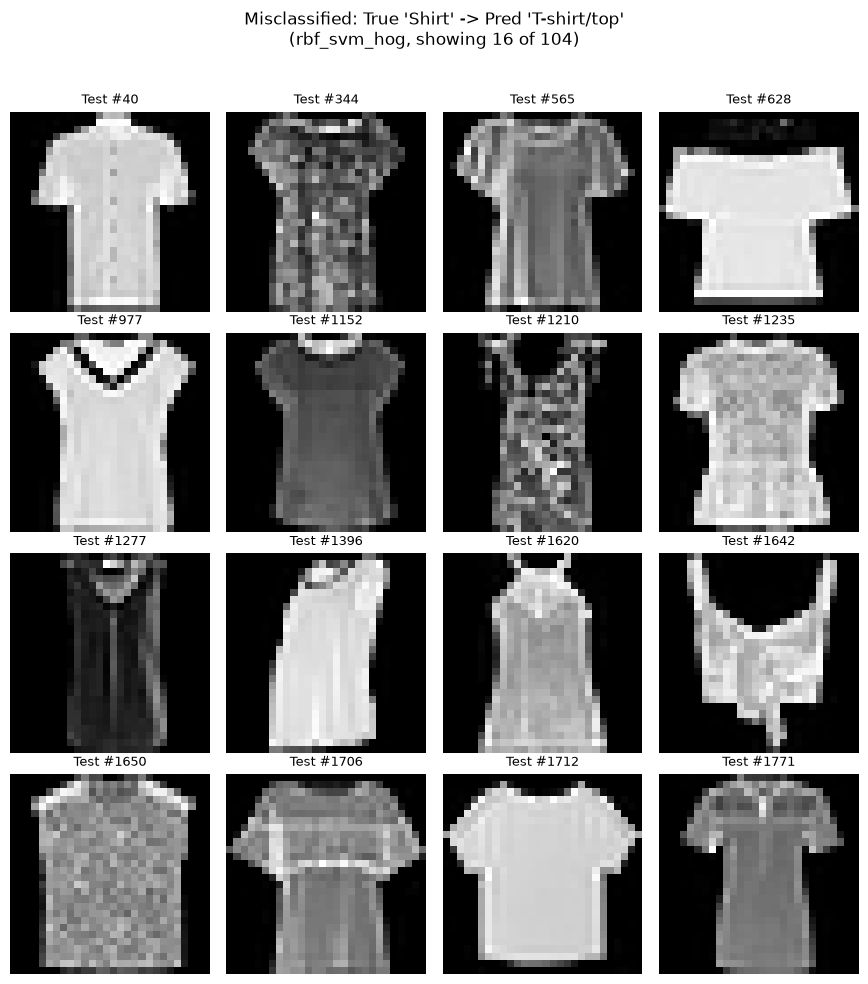

Pair 2: Actual 'T-shirt/top' misclassified as 'Shirt' (Count: 91)


saved results/figures/errors_misclassified_t-shirt_top_vs_shirt.png


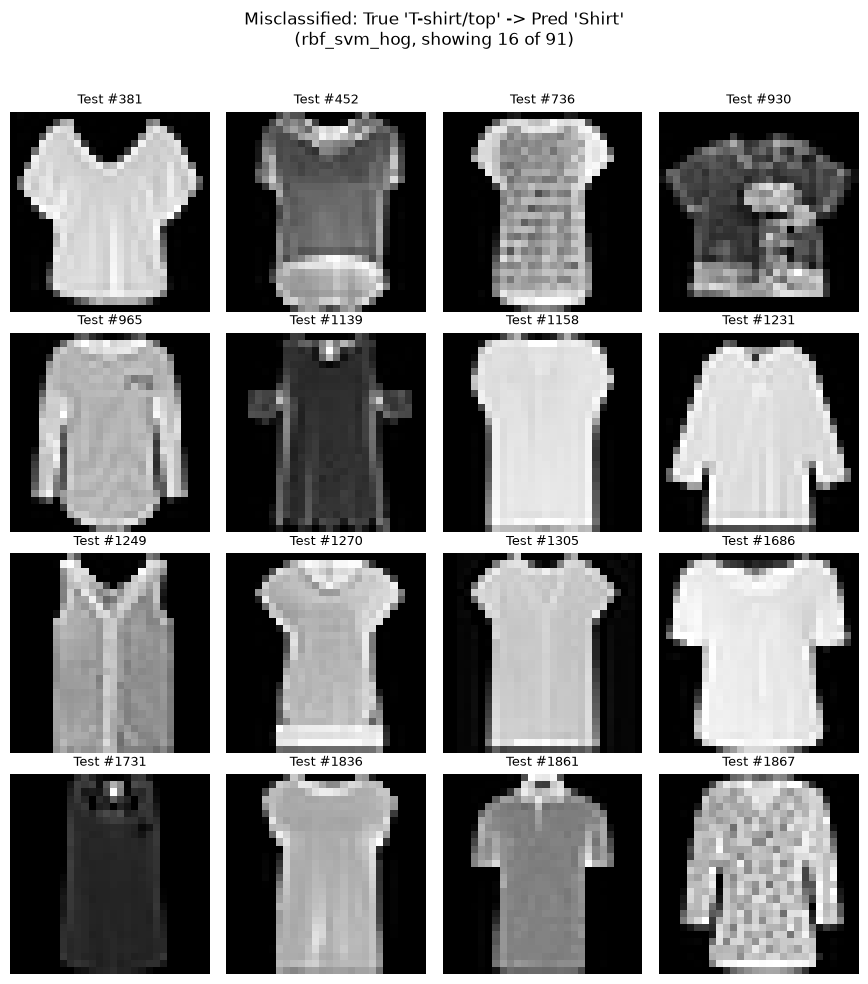

Pair 3: Actual 'Pullover' misclassified as 'Shirt' (Count: 66)


saved results/figures/errors_misclassified_pullover_vs_shirt.png


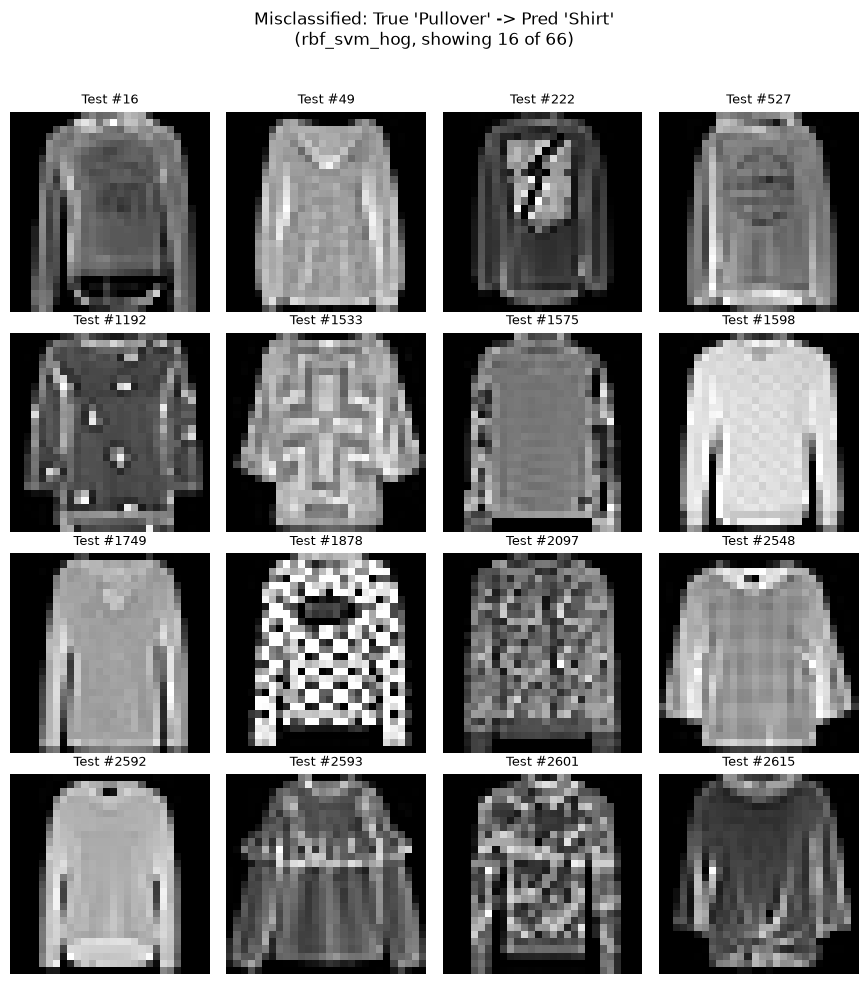

Pair 4: Actual 'Pullover' misclassified as 'Coat' (Count: 61)


saved results/figures/errors_misclassified_pullover_vs_coat.png


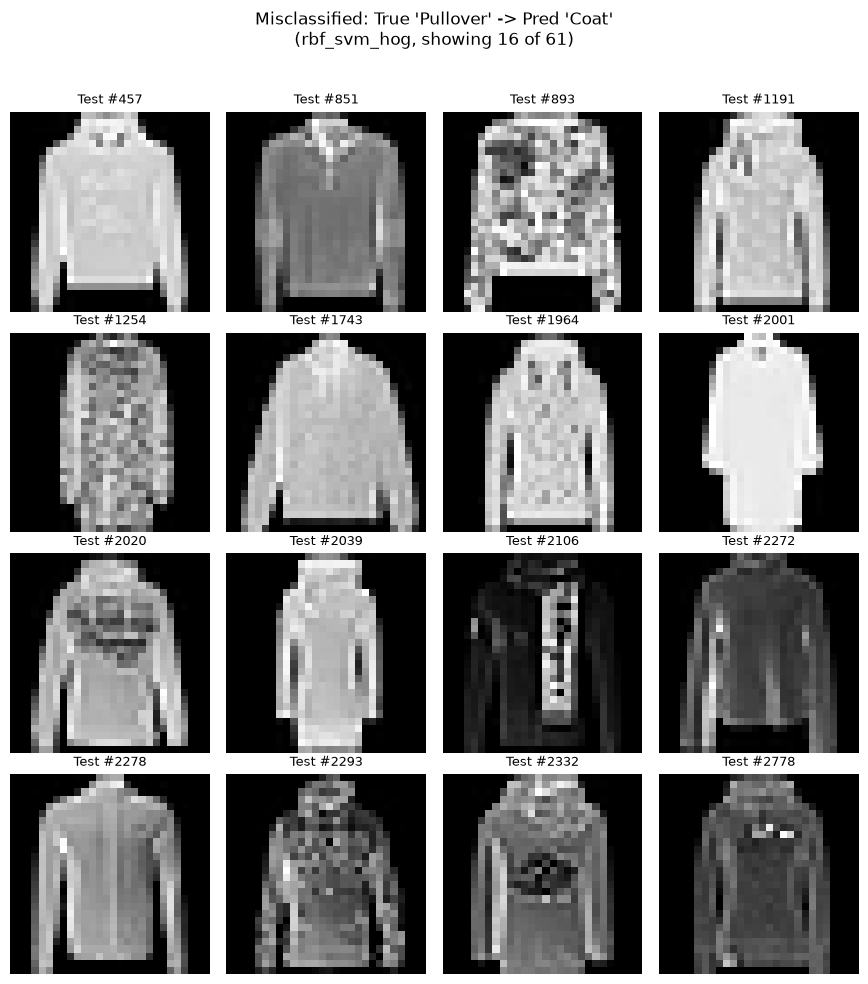

Pair 5: Actual 'Shirt' misclassified as 'Coat' (Count: 59)


saved results/figures/errors_misclassified_shirt_vs_coat.png


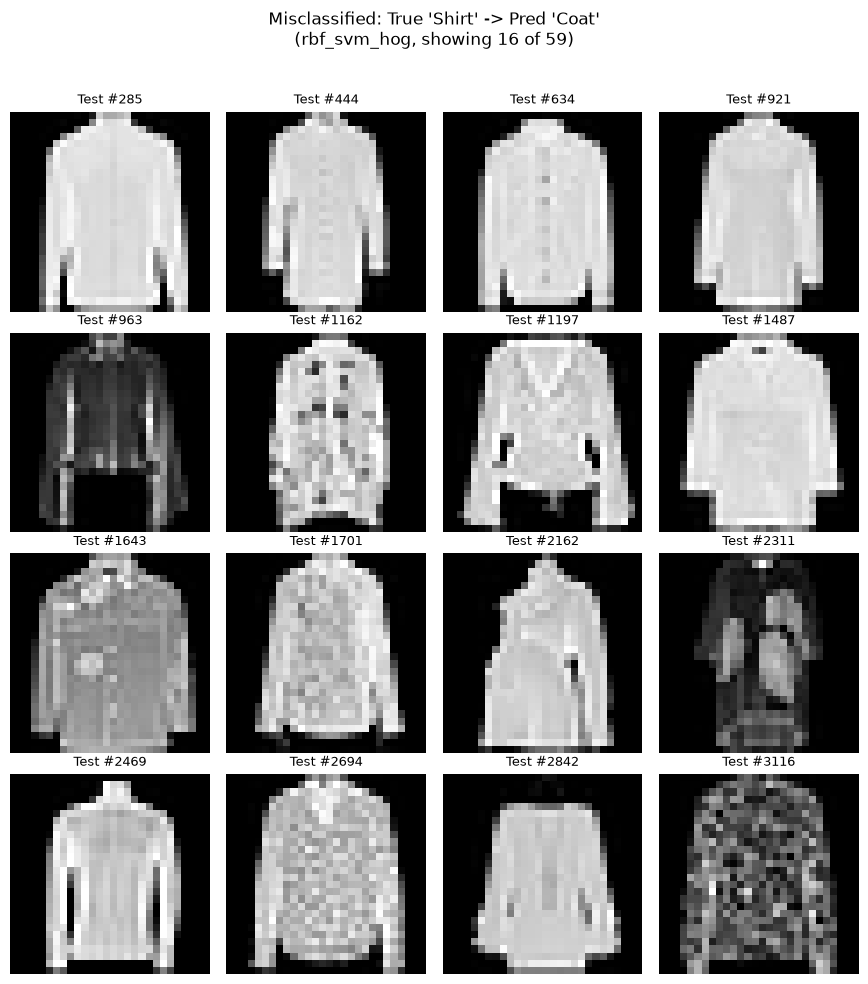

In [10]:
for idx, row in df_top_pairs.iterrows():
    true_label, pred_label = row["true"], row["pred"]
    print(f"Pair {idx+1}: Actual '{true_label}' misclassified as '{pred_label}' (Count: {row['count']})")
    fig_mis = results.plot_misclassified(best_exp, true_label, pred_label, n=16)
    plt.show()

### Qualitative Analysis of Misclassified Images
Inspecting the visual grids reveals critical insights:
- **Low Resolution Blurring:** In the 28×28 grid, collar buttons, buttonholes, pocket seams, and fabric textures dissolve into low-contrast intensity blurs.
- **Silhouette Ambiguity:** A button-down shirt worn open or untucked has an outer shape virtually indistinguishable from an open cardigan or light jacket.
- **Human Ambiguity:** Several misclassified examples are challenging even for human domain experts without color or contextual zoom. Handcrafted HOG descriptors, which pool gradients across fixed 4×4 spatial blocks, cannot learn which small details matter for these items.

## 11. Agreement Between the Two Best Models (HOG vs. Pixels)

We compare the test predictions of the two highest-scoring configurations: `rbf_svm_hog` (91.08% test acc) and `rbf_svm_pixels` (89.70% test acc) using `results.model_agreement()`.

In [11]:
agreement = results.model_agreement("rbf_svm_hog", "rbf_svm_pixels")

print("2x2 Contingency Table and Agreement Metrics:")
for k, v in agreement.items():
    print(f"  {k:20s}: {v}")

2x2 Contingency Table and Agreement Metrics:
  both_correct        : 8593
  both_incorrect      : 515
  only_a_incorrect    : 377
  only_b_incorrect    : 515
  same_wrong_label    : 391
  total               : 10000
  agreement_pct       : 89.84


### Findings on Model Agreement
- **High Overall Agreement:** The two models agree on **89.84%** of all test images (8,984 out of 10,000).
- **Mutual Correctness:** Both models correctly predict **8,593 images**.
- **Mutual Errors:** Both models simultaneously fail on **515 images**.
- **Shared Failure Modes:** Crucially, out of the 515 mutual errors, in **391 cases (75.9%)**, both models predicted the **exact same wrong label**! Two models built on very different features making the *same* mistake suggests many of these images are ambiguous in the data itself (some are hard even for a person), not random model noise. 397 of the 515 shared errors are upper-body garments (T-shirt/top, Pullover, Coat, Shirt).
- **Where HOG Triumphs:** HOG corrects **515 errors** that tripped up the raw pixels model, while introducing only **377 new errors**. So HOG fixes more mistakes than it adds: a net gain of 138 images (1.38 points), matching the test accuracy gap.

## 12. Final Synthesis: Answering RQ1 through RQ4

---

### RQ1: How accurately can classical ML classify Fashion-MNIST using raw pixels?
**Answer:** Classical ML on raw pixels achieves a performance ceiling of **89.70% test accuracy** (RBF SVM).
- Linear baselines struggle significantly: Logistic Regression achieves **84.72%** and LinearSVC achieves **83.78%**.
- k-Nearest Neighbors reaches **86.11%** (k=3, Manhattan distance, distance-weighted).
- Random Forest reaches **87.56%** (300 trees, max depth 20, $\sqrt{p}$ features per split).
- *Limitation:* Raw pixel representations contain no explicit spatial geometry or translation invariance. A pixel only says how bright one spot is, so a straight hyperplane cannot tell, for example, a shifted T-shirt from a shirt.

---

### RQ2: Does HOG systematically outperform raw pixels?
**Answer:** **Yes, for linear and kernel models, but not for decision trees.**
- **Linear models benefit dramatically:** Linear SVM gains **+5.20 percentage points** (83.78% → 88.98%) and Logistic Regression gains **+4.14 percentage points** (84.72% → 88.86%).
- **Kernel SVM reaches peak accuracy:** RBF SVM improves by **+1.38 percentage points** (89.70% → **91.08%**).
- **Random Forest slightly drops:** **-0.53 percentage points** (87.56% → 87.03%), and kNN barely changes (+0.20). Each tree split looks at one feature, and one raw pixel is more informative on its own than one HOG bin (a plausible explanation, not tested).
- *Mechanism:* HOG turns local edge directions (normalised per block, so lighting matters less) into features that linear models can use directly.

---

### RQ3: Which model gives the best trade-off between accuracy, inference speed, and model size?
**Answer:** There is no single winner; it depends on what you need (end-to-end times per 1,000 images, including ~216 ms of HOG extraction for HOG models):
1. **Fastest above 87%: Random Forest (pixels)**: 87.56%, ~12 ms, but a 366 MB model.
2. **Best accuracy for its size: LinearSVC (HOG)**: 88.98%, ~219 ms (almost all HOG extraction), 181 KB.
3. **Most accurate: RBF SVM (HOG)**: 91.08%, ~29 s (upper bound, D-028), 366 MB. Too slow for high-volume use without kernel approximations.

---

### RQ4: Which clothing classes are confused most frequently, and why?
**Answer:** Misclassifications are heavily concentrated within the **upper-body garment cluster: Shirt (Class 6), T-shirt/top (Class 0), Pullover (Class 2), and Coat (Class 4).**
- **Lowest Recall:** Shirt is the worst class for all 10 trained models (from 50.9% on LinearSVC pixels to 75.2% on RBF SVM HOG). Errors *within* these four classes are 56–66% of each model's mistakes.
- **Top Errors:** Shirt misclassified as T-shirt/top (10.4% error rate) and T-shirt/top misclassified as Shirt (9.1% error rate).
- *Root Cause:* At 28×28 grayscale resolution, garments share nearly identical outer torso silhouettes and aspect ratios. The subtle internal features required to distinguish them—collars, buttons, plackets, and fabric weave—are represented by only a handful of ambiguous pixels that fixed-grid HOG features don't capture well.

## 13. Limitations of Classical ML and Motivation for Phase 2 CNN

### 13.1 Limitations of the Classical Benchmark
1. **Hyperparameter Grid Boundaries:**
   - In Logistic Regression, validation accuracy improved monotonically as $C$ decreased, settling at $C=0.01$ (the smallest value tried, D-020).
   - In LinearSVC, optimal $C=0.01$ was also on the lower grid boundary (D-026).
   - In RBF SVM, optimal $C=10$ was on the upper grid boundary (D-027).
   - To respect scientific test discipline and avoid data snooping, these grids were not expanded post-hoc.
2. **Hardware Heterogeneity:** Phase 03 models (kNN) were timed on an Apple M3, whereas Phase 04 models (RF, SVMs) were timed on an Apple M3 Pro. Accuracy doesn't depend on the machine, but latency comparisons across phases are approximate (D-028, D-030). LR timings are excluded (D-024).
3. **Representational Bottleneck:** Classical ML treats feature extraction as a disconnected, fixed preprocessing step (HOG) followed by an independent classifier. The feature representation cannot adapt to the classification loss.

---

### 13.2 Why a Convolutional Neural Network (CNN) is the Logical Next Step (Capstone Phase 2)
The error analysis in this phase gives a clear motivation for transitioning to deep learning in Capstone Phase 2:
1. **Overcoming Handcrafted Feature Limitations:** HOG relies on fixed 4×4 spatial pooling and handcrafted gradient binning. It cannot dynamically adjust its spatial filters to isolate fine-grained details like collars or buttons.
2. **Hierarchical Representation Learning:**
   - **Low-level layers:** Learn edge filters directly from raw pixels (similar to what HOG hand-codes).
   - **Mid-level layers:** Combine edges into spatial parts: collar curves, button rows, sleeve seams, and zipper tracks.
   - **High-level layers:** Assemble parts into class-specific garment representations with learned spatial invariance.
3. **Weight Sharing and Translation Equivariance:** Convolutional kernels apply the same feature detector across the entire image, detecting collars and hemlines regardless of slight posture shifts or centering offsets.
4. **Target for Phase 2:** the upper-body confusions. Our hypothesis is that a small CNN (2–3 conv blocks, batch norm, dropout) trained on the same split will beat the 91.08% classical best, mainly by fixing Shirt / T-shirt / Pullover / Coat errors (397 of the 515 images both RBF SVMs get wrong are in these classes). Phase 2 will test this with the same `evaluate()` harness.

---
*Notebook verified and executed top-to-bottom. Capstone Phase 1 (v1) complete.*